# matplotlib 的基本用法

matplotlib 是 Python 里用得最多的绘图库，函数的设计与 MATLAB 相近，写一小段脚本就能把图画出来。官方的示例库(https://matplotlib.org/stable/gallery/index)里有几百个图与它们的源码，找一个接近的改写最快。

这一章先看怎么快速画图，再用几个例子说明 matplotlib 的绘图机制，读完这一章，就能把官方的例子改成自己要的样子，画出想要的图。

## 本章要学的内容

- 用 `pyplot` 快速画图
- 面向对象的写法
- 子图的排布方式
- 设置文件与样式
- 中文的显示
- `Artist` 对象的结构

In [1]:
import helper.magics
import numpy as np
import helper.matplotlib
from matplotlib import pyplot as plt

## 绘图的基本

matplotlib 是按面向对象写的，图里的每个部件都是对象。大的程序适合直接操作对象，但那样写起来长，为此还准备了用来快速画图的 `pyplot`，这一节从 `pyplot` 开始。

要在 Notebook 里显示图，就执行下面这条命令。

In [2]:
%matplotlib inline

用 `inline` 时，画出的图在格子执行完之后就被关闭；想在多个格子里操作同一张图，就用下面这条命令停掉自动关闭。

In [3]:
%config InlineBackend.close_figures = False

### 用 `pyplot` 画图

`pyplot` 备齐了与 MATLAB 相似的函数，能快速画出二维的图，先看一个简单的例子。

:::{admonition} `pylab` 模块
:class: note
`pylab` 是把 NumPy 与 `pyplot` 的常用函数合在一起的模块，计算与绘图可以连着写，适合在交互环境里用。本书用 `import pylab as pl` 读入它。
:::

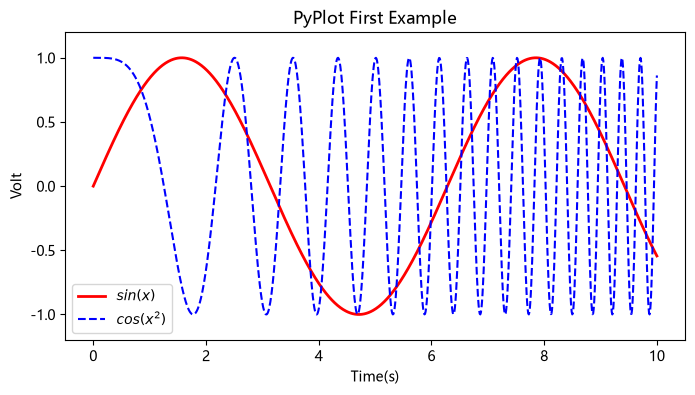

In [4]:
import matplotlib.pyplot as plt  #❶

x = np.linspace(0, 10, 1000)
y = np.sin(x)
z = np.cos(x**2)

plt.figure(figsize=(8, 4))  #❷

plt.plot(x, y, label="$sin(x)$", color="red", linewidth=2)  #❸
plt.plot(x, z, "b--", label="$cos(x^2)$")  #❹

plt.xlabel("Time(s)")  #❺
plt.ylabel("Volt")
plt.title("PyPlot First Example")
plt.ylim(-1.2, 1.2)
plt.legend()

plt.show()  #❻

先看这个程序的流程：❶ 用 `plt` 这个名字读入 `pyplot`。❷ 用 `figure()` 做出 `Figure`(图)，并把它当成当前的图；不调 `figure()` 直接 `plot()`，matplotlib 也会做出图来。`figsize` 是图的宽与高，单位是英寸；`dpi` 是每英寸的像素数，默认是 80，这张图的宽度因此是 `8*80 = 640` 像素。

❸ 有了图就用 `plot()` 画，真正画图的地方是 `Axes`(子图)：图里没有 `Axes` 时会做出一个覆盖图的大部分区域的 `Axes`，并把它当成当前的 `Axes`。`plot()` 的前两个参数是 x 与 y 的数据，线的属性则用关键字参数决定。

* `label`：图例里显示的名字，前后各加 `'$'` 就会用 LaTeX 按数式显示。
* `color`：颜色，可以是名字，也可以是 `'#'` 开头的 6 位十六进制数，还可以是 `(1.0, 0.0, 0.0)` 这样 0〜1 的组。
* `linewidth`：线的粗细，也可以写成 `lw`。

:::{warning}
用 LaTeX 的数式会让绘图慢不少。
:::

❹ 第 3 个参数 `'b--'` 把颜色与线型一起指定，`'b'` 是蓝、`'--'` 是虚线；在交互环境里写 `plt.plot?`，就会显示格式字符串的说明。

❺ 之后用函数设置 `Axes` 的属性。

* `xlabel`、`ylabel`：轴的名字。
* `title`：子图的题。
* `xlim`、`ylim`：轴的显示范围。
* `legend`：图例，把各条线的 `label` 与线型排在一起的框。

❻ 最后用 `plt.show()` 打开窗口，在 Notebook 里不需要这一步；在普通的环境里，`show()` 会一直停到窗口关闭为止。

用 `plt.savefig()` 可以把当前的图存成图像文件，格式由扩展名决定；下面的程序存成 `test.png`，因为 `dpi=120`，宽度是 `8*120 = 960` 像素。

In [5]:
plt.savefig("test.png", dpi=120)

:::{tip}
窗口关掉之后就不能再用 `savefig()` 保存，此时可以不调 `show()`，只调 `savefig()`，这样批量输出图像的程序也好写。
:::

`savefig()` 的第 1 个参数可以是文件名，也可以是文件那样的对象：写进 `io.BytesIO` 就能把图像的内容当作字节取出来，那时要用 `format` 指定格式。

In [6]:
import io

buf = io.BytesIO()  # 做出用来保存图像内容的 BytesIO 对象
plt.savefig(buf, format="png")  # 把图像按 png 格式存进 buf
buf.getvalue()[:20]  # 显示图像内容最前面的 20 字节

b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x03 '

### 面向对象地画图

matplotlib 本来是面向对象的库，线、文字、刻度这些部件都以对象的形式放在内存里，而 `pyplot` 把这种结构隐藏起来，提供 MATLAB 风格的函数。快速画图时这样很方便，但不适合大的程序，这一章因此主要说明直接操作对象的写法。

为了只靠函数就能用，`pyplot` 内部保存着“当前的图”与“当前的子图”：用 `gcf()` 取当前的 `Figure`、用 `gca()` 取当前的 `Axes`，名字来自 Get Current Figure 与 Get Current Axes。

In [7]:
fig = plt.gcf()
axes = plt.gca()
print(fig, axes)

Figure(800x400) Axes(0.125,0.11;0.775x0.77)


`pyplot` 的多数函数都在操作当前的 `Figure` 或 `Axes`，例如 `plot()`、`xlabel()`、`savefig()`。在交互环境里给函数名加上 `??` 就能读源码，下面是 `plot()` 的源码，可以看出它用 `gca()` 取到当前的 `Axes`，再调用那个 `Axes` 的 `plot()`。

```python
def plot(*args, **kwargs):
    ax = gca()
    ...
    try:
        ret = ax.plot(*args, **kwargs)
        ...
    finally:
        ax.hold(washold)
```

### 设置属性

图里的部件都是对象，属性可以用 `set_*()` 或 `setp()` 修改，`plot()` 返回的是 `Line2D` 列表，下面的例子改的就是它的属性。

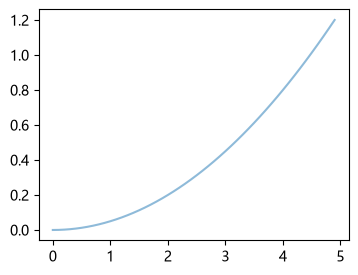

In [8]:
fig = plt.figure(figsize=(4, 3))
x = np.arange(0, 5, 0.1)
line = plt.plot(x, 0.05 * x * x)[0]  # plot 返回列表
line.set_alpha(0.5)  # 调用 Line2D 的 set_*() 方法设置属性值

用 `set_alpha()` 把线变成半透明，下面的代码一次画出正弦波与余弦波，`lines` 里就有两个 `Line2D`。

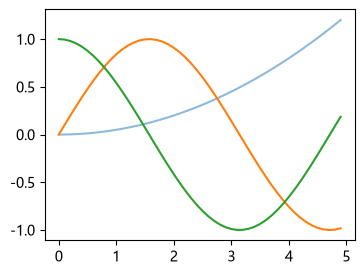

In [9]:
lines = plt.plot(x, np.sin(x), x, np.cos(x))
fig

用 `setp()` 可以一次改掉多个对象的属性。

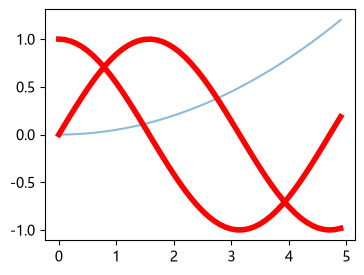

In [10]:
plt.setp(lines, color="r", linewidth=4.0)
fig

用 `get_*()` 或 `plt.getp()` 能读出属性。

In [11]:
print(line.get_linewidth())
print(plt.getp(lines[0], "color"))  # 返回 color 属性

1.5
r


与 `setp()` 不同，`getp()` 只处理一个对象，有两种用法。

* 给出属性名：返回那个属性的值。
* 不给属性名：列出全部属性与值。

下面的例子看 `Figure` 的属性。

In [12]:
plt.getp(fig)

    agg_filter = None
    alpha = None
    animated = False
    axes = [<Axes: >]
    children = [<matplotlib.patches.Rectangle object at 0x000001E...
    clip_box = None
    clip_on = True
    clip_path = None
    constrained_layout = False
    constrained_layout_pads = (None, None, None, None)
    default_bbox_extra_artists = [<Axes: >, <matplotlib.spines.Spine object at 0x00...
    dpi = 100.0
    edgecolor = (1.0, 1.0, 1.0, 1.0)
    facecolor = (1.0, 1.0, 1.0, 1.0)
    figheight = 3.0
    figure = Figure(400x300)
    figwidth = 4.0
    frameon = True
    gid = None
    in_layout = True
    label = 
    layout_engine = None
    linewidth = 0.0
    mouseover = False
    path_effects = []
    picker = None
    rasterized = False
    size_inches = [4. 3.]
    sketch_params = None
    snap = None
    suptitle = 
    supxlabel = 
    supylabel = 
    tight_layout = False
    tightbbox = TransformedBbox(     Bbox(x0=15.277777777777779, y...
    transform = IdentityTransform()
    transfor

`Figure` 的 `axes` 属性是图里子图的列表；下面的代码确认它和 `gca()` 返回的 `Axes` 是不是同一个。

In [13]:
print(plt.getp(fig, "axes"), plt.getp(fig, "axes")[0] is plt.gca())

[<Axes: >] True


用 `getp()` 也能看 `Axes` 的属性，其中 `lines` 是这个子图的 `Line2D` 的列表。

In [14]:
alllines = plt.getp(plt.gca(), "lines")
print(alllines, alllines[0] is line)  # 最先画的曲线是第 1 个元素

<a list of 3 Line2D objects> True


用这个办法就能确认对象的属性以及对象之间的关系，属性也可以直接读。

In [15]:
print(fig.axes, len(fig.axes[0].lines))

[<Axes: >] 3


### 画多个子图

`Figure` 里能放多个子图(`Axes`)：`Axes` 是绘图的区域，本书把它叫子图，到前面为止都只有一个。用 `subplot()` 就能做出多个子图。

    subplot(numRows, numCols, plotNum)

它把绘图的区域等分成 `numRows` 行 `numCols` 列，从左上往右、从上往下编号，左上角是 1，`plotNum` 就是要做的 `Axes` 的位置；3 个数都小于 10 时可以写成一个数，`subplot(323)` 与 `subplot(3, 2, 3)` 的意思相同。新的子图与前面的重叠时，前面的会被删掉。

下面的程序做出 3 行 2 列共 6 个子图，并用 `facecolor` 改颜色。

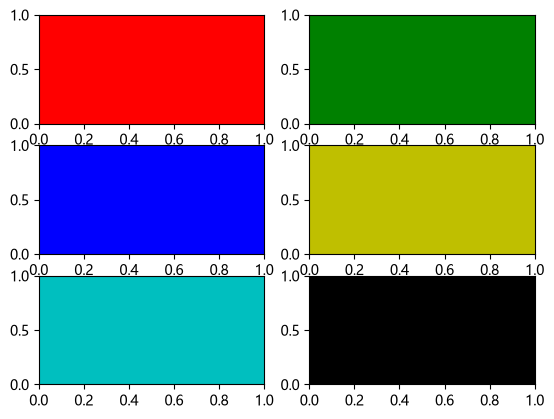

In [16]:
fig = plt.figure()
for idx, color in enumerate("rgbyck"):
    plt.subplot(321 + idx, facecolor=color)

想跨行或跨列扩展时，就像下面这样写。

<Axes: >

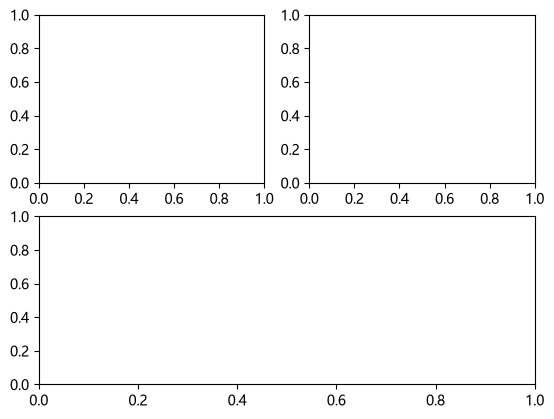

In [17]:
plt.figure()
plt.subplot(221)  # 第 1 行左边
plt.subplot(222)  # 第 1 行右边
plt.subplot(212)  # 2行目全体

窗口工具栏里的“Configure Subplots”能调整子图的间隔，从程序里则用 `subplots_adjust()` 做同样的事：参数是 `left`、`right`、`bottom`、`top`、`wspace`、`hspace` 六个，值是 0〜1 的、相对于图的宽与高的比例。

`subplot()` 会把做出来的 `Axes` 返回，把它放进变量，用 `sca()` 切换成当前的 `Axes` 再画即可；要用多张图时，就给 `figure()` 传编号，已经有同号的图就不再新建，而是把它当成当前的图。下面的程序在两张图的子图上依次画曲线。

In [18]:
plt.close("all")

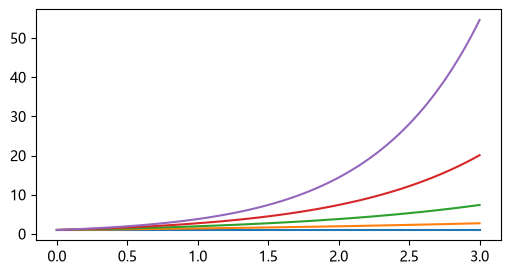

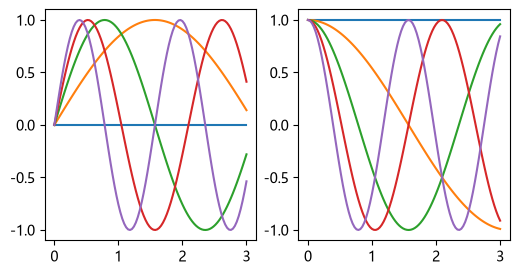

In [19]:
plt.figure(1, figsize=(6, 3))  # 做出图 1
plt.figure(2, figsize=(6, 3))  # 做出图 2
ax1 = plt.subplot(121)  # 在图 2 上做出子图 1
ax2 = plt.subplot(122)  # 在图 2 上做出子图 2

x = np.linspace(0, 3, 100)
for i in range(5):
    plt.figure(1)  #❶ 选中图 1
    plt.plot(x, np.exp(i * x / 3))
    plt.sca(ax1)  #❷ 选中图 2 的子图 1
    plt.plot(x, np.sin(i * x))
    plt.sca(ax2)  # 选中图 2 的子图 2
    plt.plot(x, np.cos(i * x))

:::{tip}
也可以不调 `sca()`，直接像 `ax1.plot()` 这样调用方法。
:::

先用 `figure()` 做出两张图，编号 1 与 2；然后在图 2 上做出左右两个子图，放进 `ax1` 与 `ax2`。

循环里 ❶ 用 `figure(1)` 把图 1 当成当前的图来画，❷ 用 `sca(ax1)` 与 `sca(ax2)` 分别把它们当成当前的子图来画；选中子图时，包含它的图也变成当前的图，因此不必再调 `figure(2)`。

用 `subplots()` 能一次做出多个子图，下面例子的 `axes` 是形状 `(2, 3)` 的数组，元素就是子图。

In [20]:
fig, axes = plt.subplots(2, 3)
[a, b, c], [d, e, f] = axes
print(axes.shape)
print(b)
plt.close(fig)

(2, 3)
Axes(0.398529,0.53;0.227941x0.35)


用 `subplot2grid()` 还能排出表那样的复杂布局，做法与做 Excel 的表很像。

```python
subplot2grid(shape, loc, rowspan=1, colspan=1, **kwargs)
```

其中 `shape` 是(行, 列)，`loc` 是子图左上角的(行, 列)，`rowspan` 与 `colspan` 是占的行数与列数。下面的例子在 3×3 的格子里做出 5 个子图，在每个子图的中央写上名字。

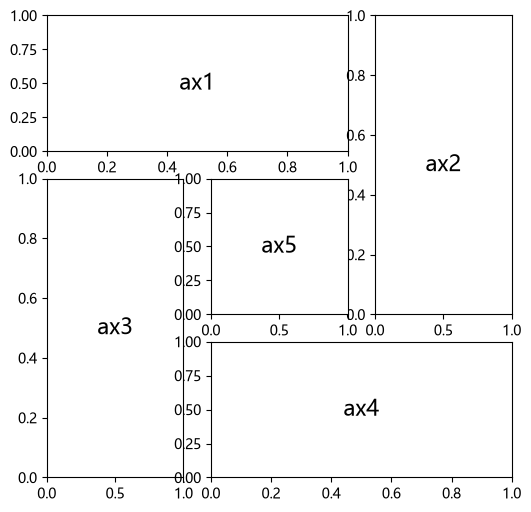

In [21]:
fig = plt.figure(figsize=(6, 6))
ax1 = plt.subplot2grid((3, 3), (0, 0), colspan=2)
ax2 = plt.subplot2grid((3, 3), (0, 2), rowspan=2)
ax3 = plt.subplot2grid((3, 3), (1, 0), rowspan=2)
ax4 = plt.subplot2grid((3, 3), (2, 1), colspan=2)
ax5 = plt.subplot2grid((3, 3), (1, 1))

for idx, ax in enumerate(fig.axes, 1):
    ax.text(0.5, 0.5, "ax{}".format(idx), ha="center", va="center", fontsize=16)

### 设置文件

要画图就得决定颜色、字体、线型这些属性，到前面为止都直接用了 matplotlib 的默认设置。默认设置放在 `matplotlibrc` 这个文件里，改它就会改掉图的默认样子。

`matplotlibrc` 按下面的顺序找，先找到的优先。

* 当前目录
* 用户的设置目录(通常是主目录下的 `.matplotlib`)，可以用 `MATPLOTLIBRC` 改。
* matplotlib 安装目录里的 `mpl-data`

用下面的代码就能知道用户的设置目录在哪里。

In [22]:
import matplotlib

matplotlib.get_configdir()

'C:\\Users\\ruoyu\\.matplotlib'

用下面的代码能知道现在用的是哪个设置文件。

In [23]:
matplotlib.matplotlib_fname()

'C:\\pixi_env\\.pixi\\envs\\default\\Lib\\site-packages\\matplotlib\\mpl-data\\matplotlibrc'

打开这个文件，看上去就像一个字典：每一类设置用“.”把键隔开，用 `rc_params()` 读进来就得到设置的字典。

In [24]:
%omit print(matplotlib.rc_params())

_internal.classic_mode: False
agg.path.chunksize: 0
animation.bitrate: -1
animation.codec: h264
...

读入 `matplotlib` 时会调用 `rc_params()`，结果放进 `rcParams`。

In [25]:
%omit print(matplotlib.rcParams)

_internal.classic_mode: False
agg.path.chunksize: 0
animation.bitrate: -1
animation.codec: h264
...

In [26]:
plt.close("all")

matplotlib 按 `rcParams` 的设置来画图，直接改这个字典，之后做的部件就会反映出来：下面脚本里的折线带上了圆形的标记。

```python
matplotlib.rcParams["lines.marker"] = "o"
plt.plot([1,2,3,2])
```

用 `rc()` 可以一次设定多个：下面的例子同时决定标记、线宽与颜色。

```python
matplotlib.rc("lines", marker="x", linewidth=2, color="red")
```

要回到默认值就调 `rcdefaults()`。

```python
matplotlib.rcdefaults()
```

手工改过设置文件之后想重新读入，就像下面这样写。

```python
matplotlib.rcParams.update( matplotlib.rc_params() )
```

:::{tip}
用 `pyplot` 模块也能调 `rcParams`、`rc`、`rcdefaults`。
:::

`matplotlib.style` 里有切换外观样式的功能，能用的样式用 `available` 就能知道。

In [27]:
from matplotlib import style

print(style.available)

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


用 `use()` 切换样式，下面是 `ggplot` 样式的例子。

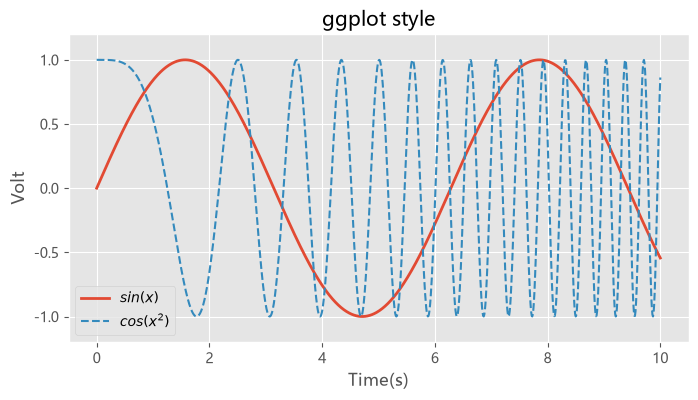

In [28]:
import numpy as np
import matplotlib.pyplot as plt

style.use("ggplot")

plt.close("all")

x = np.linspace(0, 10, 1000)
y = np.sin(x)
z = np.cos(x**2)

plt.figure(figsize=(8, 4))

plt.plot(x, y, label="$sin(x)$", linewidth=2)
plt.plot(x, z, "--", label="$cos(x^2)$")

plt.xlabel("Time(s)")
plt.ylabel("Volt")
plt.title("ggplot style")
plt.ylim(-1.2, 1.2)
plt.legend();

### 在图上显示中文

matplotlib 的默认字体(DejaVu Sans)里没有汉字字形，直接写中文就会变成豆腐块(□)，设置的办法有 3 种。

1. 每个文本单独指定字体。
2. 在程序开头改 `rcParams`。
3. 改设置文件。

字体用名字来指定，能用的字体一览可以用下面的代码取到。

In [29]:
from matplotlib.font_manager import fontManager

fontManager.ttflist[:6]

[FontEntry(fname='C:\\pixi_env\\.pixi\\envs\\default\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\STIXNonUni.ttf', index=0, name='STIXNonUnicode', style='normal', variant='normal', weight=400, stretch='normal', size='scalable'),
 FontEntry(fname='C:\\pixi_env\\.pixi\\envs\\default\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\STIXSizThreeSymReg.ttf', index=0, name='STIXSizeThreeSym', style='normal', variant='normal', weight=400, stretch='normal', size='scalable'),
 FontEntry(fname='C:\\pixi_env\\.pixi\\envs\\default\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\cmmi10.ttf', index=0, name='cmmi10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable'),
 FontEntry(fname='C:\\pixi_env\\.pixi\\envs\\default\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\STIXSizTwoSymReg.ttf', index=0, name='STIXSizeTwoSym', style='normal', variant='normal', weight=400, stretch='normal', size='scalable'),
 FontEntry(fname='C:\\pixi_env\\.pixi\\e

`ttflist` 是 matplotlib 找到的字体一览，每个元素都是 `Font`，下面的代码显示第一个字体的名字与文件。

In [30]:
print(fontManager.ttflist[0].name)
print(fontManager.ttflist[0].fname)

STIXNonUnicode
C:\pixi_env\.pixi\envs\default\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\STIXNonUni.ttf


下面的程序用一览表里的字体写中文。

In [31]:
plt.close("all")

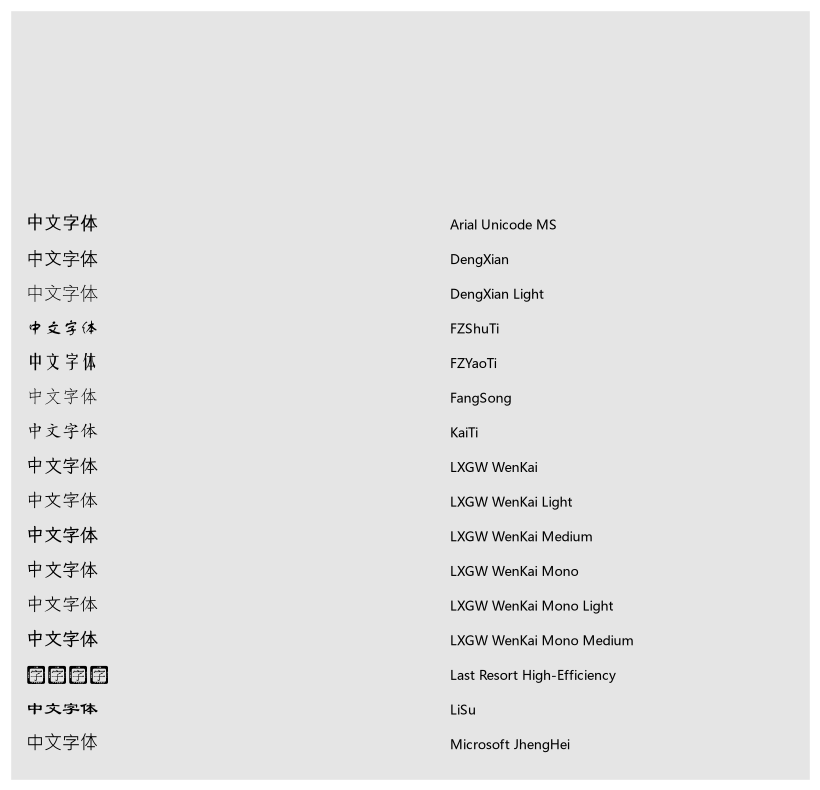

16 fonts


In [32]:
# %fig=显示系统里的中文字体名
import warnings
from matplotlib.ft2font import FT2Font
from os import path

def has_japanese(fname):
    """用有没有汉字的字形来判断是不是中文字体。"""
    try:
        face = FT2Font(fname)
    except Exception:
        return False
    return all(face.get_char_index(ord(ch)) for ch in "中文测试")

fonts = []
for font in fontManager.ttflist:
    if not path.exists(font.fname) or font.name in fonts:  #❶
        continue
    if has_japanese(font.fname):  #❷
        fonts.append(font.name)
fonts = sorted(fonts)[:16]  #❸ 太多，只取前 16 个

fig = plt.figure(figsize=(8, 0.5 + 0.45 * len(fonts)))
ax = fig.add_subplot(111)
plt.subplots_adjust(0, 0, 1, 1, 0, 0)
plt.xticks([])
plt.yticks([])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # 消掉没有字重的字体的警告
    for i, name in enumerate(fonts[::-1]):
        y = 0.04 + i * 0.045
        ax.text(0.02, y, "中文字体", {"fontname": name, "fontsize": 13}, transform=ax.transAxes)
        ax.text(0.55, y, name, {"fontsize": 9}, transform=ax.transAxes)
plt.show()
print(len(fonts), "fonts")

❶ 同一个字体名会出现很多次，先按名字去重。❷ 用 `FT2Font.get_char_index()` 查有没有汉字的字形，只留下中文字体；如果按文件大小来筛，那些不含汉字的大字体也会混进来。❸ 数量太多，排序之后只显示前 16 个。

这里出现的名字可以直接写进 `fontname`。

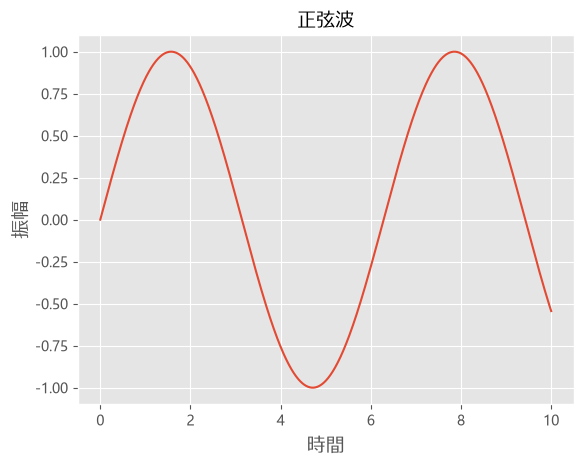

In [33]:
from matplotlib.font_manager import FontProperties

font = FontProperties(fname=r"c:\windows\fonts\meiryo.ttc", size=14)  #❶
t = np.linspace(0, 10, 1000)
y = np.sin(t)
plt.close("all")
plt.plot(t, y)
plt.xlabel("時間", fontproperties=font)  #❷
plt.ylabel("振幅", fontproperties=font)
plt.title("正弦波", fontproperties=font)
plt.show()

❶ 做出 `FontProperties`，把字体文件的绝对路径放进 `fname`，❷ 把这个对象传给 `fontproperties`。

也可以把 TTC 拆成 TTF 放进系统的字体文件夹，不过 matplotlib 启动时不会重新读所有字体，加了文件之后要删掉设置文件夹里的 `fontlist-*.json`。

改 `rcParams` 就不必每个文本都指定一遍，本书用 `helper.fonts` 来挑适合当前环境的字体。

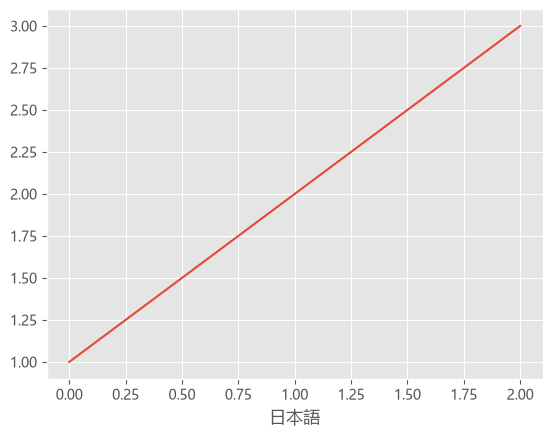

In [34]:
import helper.fonts

plt.rcParams["font.family"] = helper.fonts.current()  # 这个环境里能用的中文字体
plt.figure()
plt.plot([1, 2, 3])
plt.xlabel("日本語");

## `Artist` 对象

matplotlib 分成 3 层。

* `backend_bases.FigureCanvas`：用来画图的画布。
* `backend_bases.Renderer`：知道往画布上画的方法。
* `artist.Artist`：知道用 Renderer 往画布上画的方法。

`FigureCanvas` 与 `Renderer` 负责往 GUI 的部件上画这类底层的工作，而 `Artist` 负责图、文字、曲线这些部件的绘制与排布，通常只碰 `Artist` 就够了。

`Artist` 里既有单独的部件(`Line2D`、`Rectangle`、`Text`、`AxesImage`)，也有把别的 `Artist` 汇总起来的容器(`Axis`、`Axes`、`Figure`)。

做出 `Artist` 来画图的步骤是这样的。

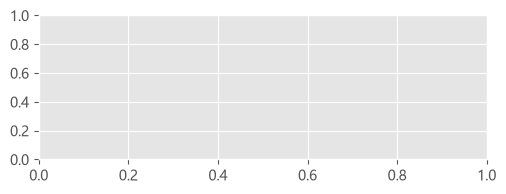

In [35]:
fig = plt.figure()
ax = fig.add_axes([0.15, 0.1, 0.7, 0.3])

* 做 `Figure`。
* 在这个 `Figure` 里做 1 个以上的 `Axes`。
* 用 `Axes` 的方法做部件。

下面的程序用 `figure()` 做 `Figure`：`figure()` 会一并做好初始化，比直接用 `Figure()` 安全；然后用 `add_axes()` 做 `Axes`，参数是 `[left, bottom, width, height]`，用 0〜1 表示它在图里的位置与大小。

In [36]:
line = ax.plot([1, 2, 3], [1, 2, 1])[0]  # 返回的是只有 1 个元素的列表
print(line is ax.lines[0])

True


用 `Axes` 的 `plot()` 画出曲线，它返回那条 `Line2D`。

In [37]:
ax.set_xlabel("time");

`Axes` 的 `lines` 是这个子图的曲线列表，每调一次 `plot()` 就往里加一条，想删掉的曲线就从这里删。

`Axes` 里还有很多别的 `Artist`，x 轴的名字用 `set_xlabel()` 来设。

In [38]:
print(ax.xaxis)
print(ax.xaxis.label)
print(ax.xaxis.label._text)

XAxis(96.0,48.0)
Text(0.5, 17.924587673611114, 'time')
time


`set_xlabel()` 的内容就是下面这一行。

    self.xaxis.set_label_text(xlabel)

`Axes` 的 `xaxis` 属性是 `XAxis`；它的 `label` 属性是 `Text`，而 `Text` 的 `_text` 就是设进去的字符串。

In [39]:
ax.get_xaxis().get_label().get_text()

'time'

`Axes`、`XAxis`、`Text` 都从 `Artist` 派生，因此用 `get_*()` 也能读出值。

### `Artist` 的属性

In [40]:
fig = plt.figure()
fig.patch.set_color("g")  # 把背景设成绿色

<Figure size 640x480 with 0 Axes>

图里的部件都是 `Artist`，都带着决定外观的属性。`Figure` 与 `Axes` 有背景的 `patch`，它是 `Rectangle`，改它就会改掉背景的颜色与透明度，下面的例子把背景改成绿色。

当作单独的程序运行时，只调 `set_color()` 画面不会变，要用 `fig.canvas.draw()` 重画。

所有 `Artist` 都有的属性汇总如下。

| 属性  | 说明  |
|:--|:--|
| `alpha`  | 透明度，0 透明、1 不透明 |
| `animated`  | 是否按动画绘制 |
| `axes`  | 持有这个 `Artist` 的 `Axes`(有时是 `None`) |
| `clip_box`  | 裁剪的范围 |
| `clip_on`  | 是否裁剪 |
| `clip_path`  | 裁剪的形状 |
| `contains`  | 判断点是否在它上面的函数 |
| `figure`  | 持有这个 `Artist` 的 `Figure`(有时是 `None`) |
| `label`  | 图例里显示的名字 |
| `picker`  | 选取的方式 |
| `transform` | 坐标的变换(移动、旋转、放大) |
| `visible` | 是否显示 |
| `zorder` | 绘制的顺序 |

属性用对应的 `get_*()` 与 `set_*()` 读写，下面的代码把画出的线变成半透明。

In [41]:
line = plt.plot([1, 2, 3, 2, 1], lw=4)[0]
line.set_alpha(0.5)

用 `set()` 能一次改掉多个属性。

In [42]:
line.set(alpha=0.5, zorder=2);

用 `getp()` 能把属性的一览与值一起看。

In [43]:
plt.getp(fig.patch)

    agg_filter = None
    alpha = None
    angle = 0.0
    animated = False
    antialiased or aa = False
    bbox = Bbox(x0=0.0, y0=0.0, x1=1.0, y1=1.0)
    capstyle = butt
    center = [0.5 0.5]
    children = []
    clip_box = None
    clip_on = True
    clip_path = None
    corners = [[0. 0.]  [1. 0.]  [1. 1.]  [0. 1.]]
    data_transform = BboxTransformTo(     TransformedBbox(         Bbox...
    edgecolor or ec = (0.0, 0.5, 0.0, 1)
    edgegapcolor = None
    extents = Bbox(x0=0.0, y0=0.0, x1=640.0, y1=480.0)
    facecolor or fc = (0.0, 0.5, 0.0, 1)
    figure = Figure(640x480)
    fill = True
    gid = None
    hatch = None
    hatch_linewidth = 1.0
    hatchcolor = (0.0, 0.5, 0.0, 1)
    height = 1
    in_layout = False
    joinstyle = miter
    label = 
    linestyle or ls = solid
    linewidth or lw = 0.0
    mouseover = False
    patch_transform = CompositeGenericTransform(     BboxTransformTo(   ...
    path = Path(array([[0., 0.],        [1., 0.],        [1.,...
    path_e

In [44]:
plt.close("all")

### `Figure` 这个容器

属性的看法说明完了，接下来是怎么找到想要的那个 `Artist`：`Artist` 里既有单独的部件，也有容器，这里看容器。

最上层的 `Artist` 是 `Figure`，图里所有的要素都包含在它里面。用 `add_subplot()` 或 `add_axes()` 添加子图时，它们会进 `axes` 列表，而方法会返回做出来的 `Axes`；返回的类型分别是 `AxesSubplot` 与 `Axes`，其中 `AxesSubplot` 从 `Axes` 派生。

True


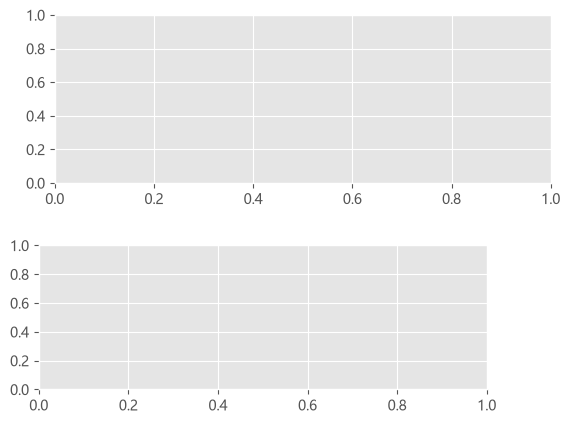

In [45]:
fig = plt.figure()
ax1 = fig.add_subplot(211)
ax2 = fig.add_axes([0.1, 0.1, 0.7, 0.3])
print(ax1 in fig.axes and ax2 in fig.axes)

为了 `gca()`，`Figure` 在内部保存着当前轴的信息，因此不要直接动 `axes`，而要用 `add_subplot()`、`add_axes()`、`delaxes()`；用 `for` 遍历各元素则没有问题。下面的代码显示所有子图的网格。

In [46]:
for ax in fig.axes:
    ax.grid(True)

`Figure` 自己也能持有文字、线、图像，默认的坐标是像素，但改掉 `transform` 就能用别的坐标：`Figure` 的坐标是左下角 `(0,0)`、右上角 `(1,1)`，坐标变换放到后面的章节说明。下面的程序往图里加两条线。

In [47]:
plt.close("all")

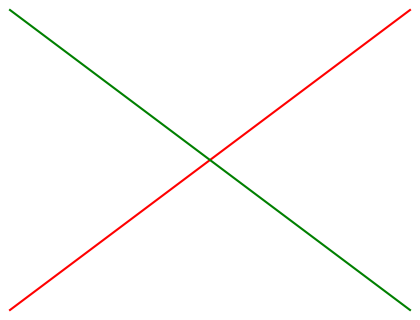

In [48]:
from matplotlib.lines import Line2D

fig = plt.figure(figsize=(4, 3))
line1 = Line2D([0, 1], [0, 1], transform=fig.transFigure, figure=fig, color="r")
line2 = Line2D([0, 1], [1, 0], transform=fig.transFigure, figure=fig, color="g")
fig.lines.extend([line1, line2])

把 `fig.transFigure` 当作 `transform` 传给 `Line2D`，就会按 `Figure` 的坐标来画；用 `figure=fig` 告诉它是哪张图的，最后再加进 `fig.lines` 列表。

`Figure` 持有的 `Artist` 属性如下。

| 属性  | 说明  |
|:--|:--|
| `axes`  | `Axes` 的列表 |
| `patch`  | 背景的 `Rectangle` |
| `images`  | `FigureImage` 的列表 |
| `legends`  | `Legend` 的列表 |
| `lines`  | `Line2D` 的列表 |
| `patches`  | `Patch` 的列表 |
| `texts`  | `Text` 的列表 |

### `Axes` 这个容器

`Axes`(子图)是 matplotlib 的中心，里面包含很多 `Artist`，也带着做出与修改它们的各种方法。与 `Figure` 一样有背景的 `patch`：直角坐标时是 `Rectangle`、极坐标时是 `Circle`。下面的代码把背景改成绿色。

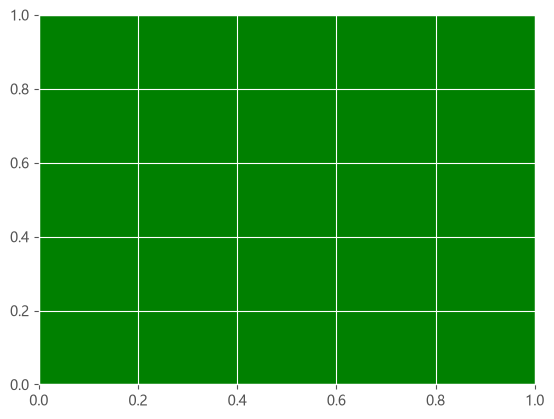

In [49]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.patch.set_facecolor("green")

调 `plot()` 会做出 `Line2D`，加进 `Axes` 的 `lines`，并返回做出来的那些；`plot()` 的关键字参数会原样变成 `Line2D` 的属性。

In [50]:
x, y = np.random.rand(2, 100)
line = ax.plot(x, y, "-", color="blue", linewidth=2)[0]
line is ax.lines[0]

True

`plot()` 之所以返回列表，是因为可以传入好几组 x 与 y，一次画出多条曲线。

`bar()` 与 `hist()` 做出 `Patch` 的列表，内容是 `Patch` 派生的 `Rectangle`，加进 `Axes` 的 `patches`。

True

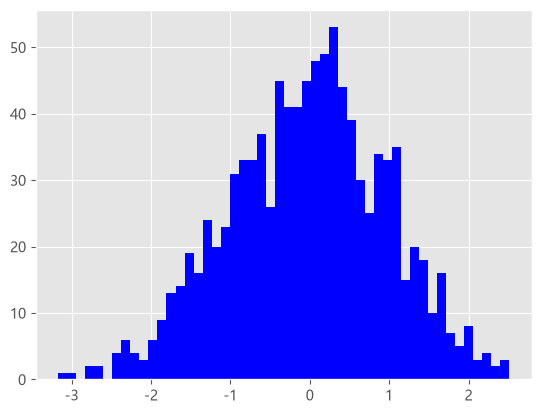

In [51]:
fig, ax = plt.subplots()
n, bins, rects = ax.hist(np.random.randn(1000), 50, facecolor="blue")
rects[0] is ax.patches[0]

通常不直接动 `lines` 与 `patches`，而用 `add_line()` 与 `add_patch()`，它们会帮忙把属性设置好。先做出 `Axes` 与 `Rectangle`。

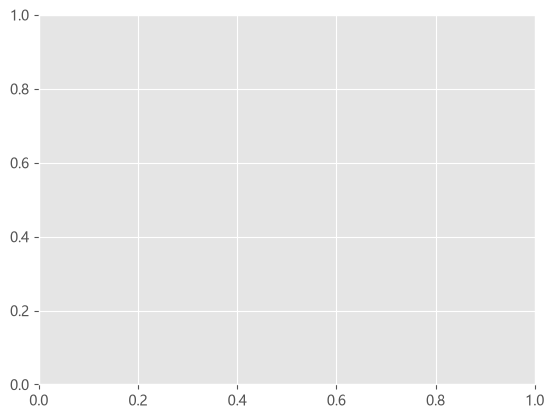

In [52]:
fig, ax = plt.subplots()
rect = plt.Rectangle((1, 1), width=5, height=12)

用 `add_patch()` 把 `rect` 加到 `ax` 里。

In [53]:
ax.add_patch(rect)  # 把 rect 加到 ax 里
rect.axes is ax

True

为了让 `rect` 整个显示出来，用 `autoscale_view()` 把轴的范围调好。

In [54]:
print(ax.get_xlim())  # ax 的 x 轴范围是 0 到 1，显示不全 rect
print(ax.dataLim.bounds)  # 数据的范围与 rect 的大小一致
ax.autoscale_view()  # 自动调整坐标轴的范围
print(ax.get_xlim())  # 这样 x 轴就能完整显示 rect

(np.float64(0.0), np.float64(1.0))
(np.float64(1.0), np.float64(1.0), np.float64(5.0), np.float64(12.0))
(np.float64(0.75), np.float64(6.25))


`Axes` 持有的 `Artist` 属性如下。

| 属性  | 说明  |
|:--|:--|
| `artists`  | `Artist` 的列表 |
| `patch`  | 背景的 `Patch`(`Rectangle` 或 `Circle`) |
| `collections`  | `Collection` 的列表 |
| `images`  | `AxesImage` 的列表 |
| `legends`  | `Legend` 的列表 |
| `lines`  | `Line2D` 的列表 |
| `patches`  | `Patch` 的列表 |
| `texts`  | `Text` 的列表 |
| `xaxis`  | `XAxis` |
| `yaxis`  | `YAxis` |

`Axes` 里做出 `Artist` 的方法如下。

| 方法  | 做出来的对象  | 进入的列表  |
|:--|:--|:--|
| `annotate` | `Annotation` | `texts` |
| `bar` | `Rectangle` | `patches` |
| `errorbar` | `Line2D`、`Rectangle` | `lines`、`patches` |
| `fill` | `Polygon` | `patches` |
| `hist` | `Rectangle` | `patches` |
| `imshow` | `AxesImage` | `images` |
| `legend` | `Legend` | `legends` |
| `plot` | `Line2D` | `lines` |
| `scatter` | `PathCollection` | `collections` |
| `text` | `Text` | `texts` |

下面的程序用 `scatter()` 画散点图，它返回 `PathCollection`。

In [55]:
fig, ax = plt.subplots()
t = ax.scatter(np.random.rand(20), np.random.rand(20))
print(t, t in ax.collections)
plt.close("all")

<matplotlib.collections.PathCollection object at 0x000001E920ED3A10> True


### `Axis` 这个容器

`Axis` 里放着刻度线、刻度的文字、网格与轴的名字。刻度有主刻度与副刻度，用 `get_major_ticks()` 与 `get_minor_ticks()` 取；刻度是 `XTick` 或 `YTick`，带着线与文字，用 `get_ticklabels()` 与 `get_ticklines()` 能一次取出来。

先做出子图，再取 x 轴。

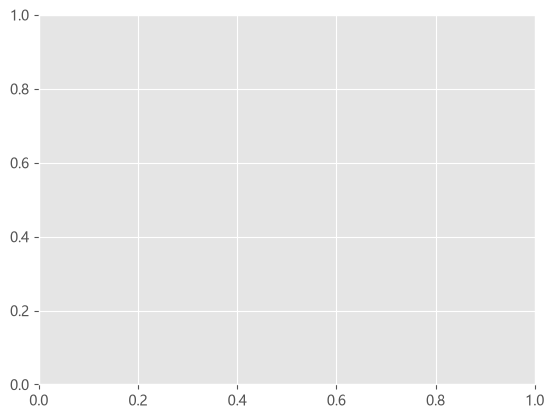

In [56]:
fig, ax = plt.subplots()
axis = ax.xaxis

取出刻度位置的列表。

In [57]:
axis.get_ticklocs()

array([0. , 0.2, 0.4, 0.6, 0.8, 1. ])

取出刻度的标签，以及它的文字。

In [58]:
print(axis.get_ticklabels())  # 取到刻度标签的列表
print([x.get_text() for x in axis.get_ticklabels()])  # 取到刻度的文字

[Text(0.0, 0, '0.0'), Text(0.2, 0, '0.2'), Text(0.4, 0, '0.4'), Text(0.6000000000000001, 0, '0.6'), Text(0.8, 0, '0.8'), Text(1.0, 0, '1.0')]
['0.0', '0.2', '0.4', '0.6', '0.8', '1.0']


取出主刻度的线的列表，上下两个轴各有一份。

In [59]:
axis.get_ticklines()

<a list of 12 Line2D ticklines objects>

副刻度没有设置，列表因此是空的。

In [60]:
axis.get_ticklines(minor=True)  # 取到副刻度线的列表

<a list of 0 Line2D ticklines objects>

刻度线与文字的属性都能改：下面的代码把文字改成红色、转 45 度，把线改成绿色的粗线。

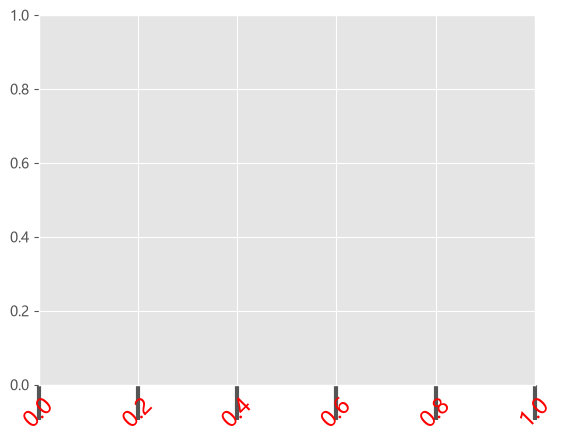

In [61]:
for label in axis.get_ticklabels():
    label.set_color("red")
    label.set_rotation(45)
    label.set_fontsize(16)

for line in axis.get_ticklines():
    line.set_color("green")
    line.set_markersize(25)
    line.set_markeredgewidth(3)
fig

这个例子是为了说明属性，实际写的时候用 `xticks()` 就能一次设好刻度的文字，不过 `xticks()` 只能改文字，改不了线，源码请用 `plt.xticks??` 读。

    plt.xticks(fontsize=16, color="red", rotation=45)

副刻度的列表是空的，因为决定位置的默认是 `NullLocator`；主刻度则是 `AutoLocator`，它按放大的状态等条件来定位置。

In [62]:
print(axis.get_minor_locator())  # 计算副刻度位置的对象
print(axis.get_major_locator())  # 计算主刻度位置的对象

matplotlib 里有决定刻度位置的 `Locator` 与决定文字的 `Formatter`。下面的程序把 x 轴的主刻度设成 $\pi/4$、副刻度设成 $\pi/20$，主刻度的文字用 $\pi$ 表示。

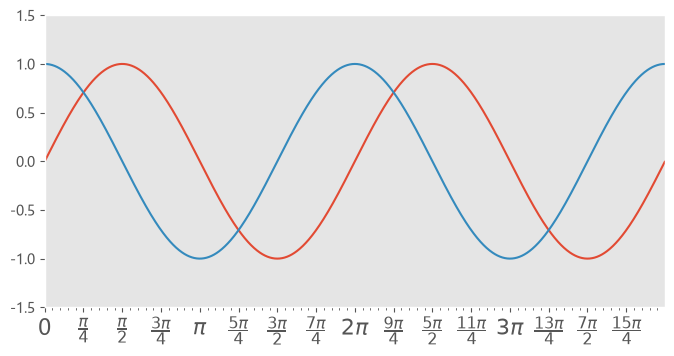

In [63]:
from fractions import Fraction
from matplotlib.ticker import MultipleLocator, FuncFormatter  #❶

x = np.arange(0, 4 * np.pi, 0.01)
fig, ax = plt.subplots(figsize=(8, 4))
plt.plot(x, np.sin(x), x, np.cos(x))


def pi_formatter(x, pos):  #❷
    frac = Fraction(int(np.round(x / (np.pi / 4))), 4)
    d, n = frac.denominator, frac.numerator
    if frac == 0:
        return "0"
    elif frac == 1:
        return r"$\pi$"
    elif d == 1:
        return r"${%d} \pi$" % n
    elif n == 1:
        return r"$\frac{\pi}{%d}$" % d
    return r"$\frac{%d \pi}{%d}$" % (n, d)


# 设置两个轴的范围
plt.ylim(-1.5, 1.5)
plt.xlim(0, np.max(x))

# 设置图下方的留白
plt.subplots_adjust(bottom=0.15)

plt.grid()  # 打开网格

# 把主刻度设成 pi/4
ax.xaxis.set_major_locator(MultipleLocator(np.pi / 4))  #❸

# 用 pi_formatter 函数算主刻度的文字
ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))  #❹

# 把副刻度设成 pi/20
ax.xaxis.set_minor_locator(MultipleLocator(np.pi / 20))  #❺

# 设置刻度文字的大小
for tick in ax.xaxis.get_major_ticks():
    tick.label1.set_fontsize(16)

❶ 刻度的位置与文字的类在 `matplotlib.ticker` 里，这里读入两个。

* `MultipleLocator`：❸❺ 把刻度放在指定值的整数倍上。
* `FuncFormatter`：❹ 用指定的函数做出文字，函数会收到刻度的值与编号，❷ `pi_formatter()` 就是那个函数，按值返回 $\pi$ 的分数。

### 看 `Artist` 之间的关系

为了看清图里各 `Artist` 之间的关系，本书准备了一个输出关系图的小程序。

要出图得先装好 Graphviz，或者用在线编辑器。下面的代码用 `GraphvizMatplotlib.graphviz()` 把 `fig` 里的关系按 DOT 语言输出，再用 `graphviz` 变成 SVG。

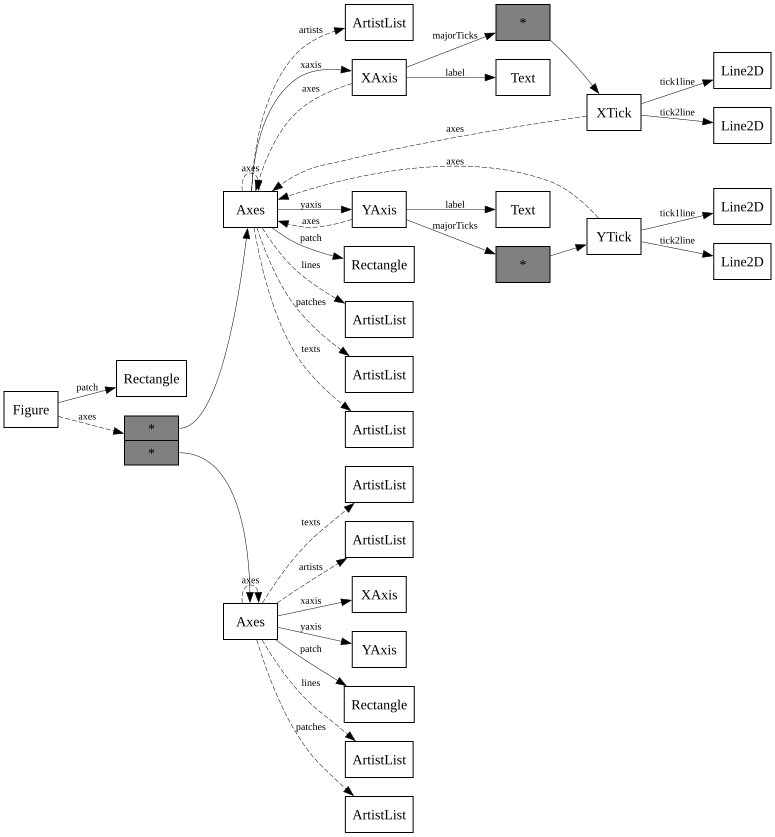

In [64]:
fig = plt.figure()
plt.subplot(211)
plt.bar([1, 2, 3], [1, 2, 3])
plt.subplot(212)
plt.plot([1, 2, 3])

from helper.dot import GraphvizMatplotlib
import graphviz

plt.close(fig)
graphviz.Source(GraphvizMatplotlib.graphviz(fig))

这张图里灰色的方块是列表，别的方块是 `Artist`，关系用细箭头表示，旁边的文字是属性名。

例如从 `Figure` 指向 `Rectangle` 的箭头，意思是 `Figure` 的 `patch` 是 `Rectangle`；`Figure` 的 `axes` 是带两个元素的列表，每个元素都是 `AxesSubplot`。请一边看图一边在交互环境里敲对应的代码，确认这些关系。

## 小结

* `pyplot` 的函数在操作当前的 `Figure` 与 `Axes`，快速画图用这些就够。
* 大的程序里自己做出 `Figure` 与 `Axes`，再用方法做部件。
* 子图用 `subplot()`、`subplots()`、`subplot2grid()` 来排。
* 外观的默认值由 `rcParams` 与 `matplotlibrc` 决定，用 `style.use()` 能切换样式。
* 要显示中文就得设置字体：TTF 用名字指定，TTC 则把路径传给 `FontProperties`，本书用 `helper.fonts`。
* 图里的部件都是 `Artist`，按 `Figure` → `Axes` → `Axis`/`Line2D`/`Text` 的层次嵌套。
* 刻度的位置由 `Locator` 决定，文字由 `Formatter` 决定。